# API Trade Data Exploration

This notebook demonstrates how to use the `TRADE_MAP_API` mapping to fetch, process, and visualize trade data from an API source.

In [1]:
from pathlib import Path

path = Path(r"../data/raw/api/bulk/Comtrade_bulk_441012_001.bin")

#E:\Projects\vacoda\data\raw\api\bulk\Comtrade_bulk_441012_001.bin
print("Size MB:", path.stat().st_size / 1024 / 1024)


Size MB: 45.27596473693848


In [2]:

with open(path, "rb") as f:
    head = f.read(100)

print(head)

b'\x1f\x8b\x08\x08\xb4\xbd\xdce\x02\xffC_A_100_202301_H6_O.txt\x00\xbc\xbd[\xaf&\xb9\xb1\x1d\xf8\xfc\x19\x98\x9f2\t\x06\xef|<\xa3\x99c\x0b\xb0-yl\x8f\x8f\x1f\x1bR\x1f\xb9\x01\x1dIn\xb518\xff~"\x98\x8c`\x04\xbf\xbdwU3\x89\x01\xa4\xe2\xca\xac\xae]Y\x99\xbc\xc4e'


In [3]:
import gzip
from pathlib import Path
import pandas as pd

path = Path(r"../data/raw/api/bulk/Comtrade_bulk_441012_001.bin")

with gzip.open(path, "rt", encoding="utf-8", errors="replace") as f:
    df_head = pd.read_csv(f, sep=None, engine="python", nrows=10)

print(df_head.head())
print(df_head.columns.tolist())

         datasetCode typeCode freqCode  refPeriodId  refYear  refMonth  \
0  20100202301202100        C        A     20230101     2023        52   
1  20100202301202100        C        A     20230101     2023        52   
2  20100202301202100        C        A     20230101     2023        52   
3  20100202301202100        C        A     20230101     2023        52   
4  20100202301202100        C        A     20230101     2023        52   

   period  reporterCode flowCode  partnerCode  ...    netWgt  \
0    2023           100       DX           51  ...     0.000   
1    2023           100        M          251  ...    23.352   
2    2023           100      XOP            0  ...  2126.000   
3    2023           100       DX          288  ...     0.000   
4    2023           100        X          604  ...   108.000   

  isNetWgtEstimated grossWgt  isGrossWgtEstimated  CIFValue   FOBValue  \
0                 0      0.0                    0       NaN   4982.402   
1                 1   

In [15]:
import gzip
import pandas as pd
from pathlib import Path

path = Path(r"../data/raw/api/bulk/Comtrade_bulk_441012_001.bin")

target = "441012"
total_rows = 0
target_rows = 0
flow_counts = {}

with gzip.open(path, "rt", encoding="utf-8", errors="replace") as f:
    for chunk in pd.read_csv(f, dtype=str, sep="\t", chunksize=200_000):
        total_rows += len(chunk)
        print(f"total rows : {total_rows}")
        print([c for c in chunk.columns if "cmd" in c.lower() or "commodity" in c.lower()])

        mask = (chunk["cmdCode"] == target)
        target_rows += mask.sum()

        if mask.any():
            print("Found in:", path.name)
            print(chunk.loc[mask].head())

            if "flowCode" in chunk.columns:
                counts = chunk.loc[mask, "flowCode"].value_counts()
                for k, v in counts.items():
                    flow_counts[k] = flow_counts.get(k, 0) + int(v)

print("Total rows scanned:", total_rows)
print("Rows for 441012:", target_rows)
print("Flow counts for 441012:", flow_counts)

total rows : 200000
['cmdCode']
Found in: Comtrade_bulk_441012_001.bin
             datasetCode typeCode freqCode refPeriodId refYear refMonth  \
15955  20100202301202100        C        A    20230101    2023       52   
17604  20100202301202100        C        A    20230101    2023       52   
26222  20100202301202100        C        A    20230101    2023       52   
36087  20100202301202100        C        A    20230101    2023       52   
47486  20100202301202100        C        A    20230101    2023       52   

      period reporterCode flowCode partnerCode  ...      netWgt  \
15955   2023          100       DX         804  ...     44250.0   
17604   2023          100        X           0  ...  48156977.0   
26222   2023          100        X         788  ...      3321.0   
36087   2023          100       DX           0  ...  16265306.0   
47486   2023          100        X           8  ...     12182.0   

      isNetWgtEstimated grossWgt isGrossWgtEstimated CIFValue      FOBValue

In [5]:
print([c for c in df_head.columns if "cmd" in c.lower() or "commodity" in c.lower()])

['cmdCode']


In [6]:
df_head['cmdCode'].value_counts()

cmdCode
11        1
9615      1
750890    1
94        1
6106      1
1207      1
7413      1
844711    1
7326      1
560122    1
Name: count, dtype: int64

In [ ]:
# 1. Import Required Libraries
import os
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from vacoda.mappings.trade_map import standardize_trade_columns


## 2. Set Up TRADE_MAP_API Credentials

Store your API credentials securely. Here, we use environment variables for demonstration. Replace with your actual method as needed.

In [ ]:
# Set your API credentials (replace with your actual credentials or use a config file)
API_KEY = os.getenv('TRADE_API_KEY', 'your_api_key_here')
API_BASE_URL = 'https://api.example.com/trade'  # Replace with actual API endpoint

## 3. Test API Connection

Send a test request to verify your credentials and connection.

In [ ]:
# Test API connection (replace endpoint and params as needed)
response = requests.get(f"{API_BASE_URL}/ping", headers={"Authorization": f"Bearer {API_KEY}"})
if response.status_code == 200:
    print("API connection successful!")
else:
    print(f"API connection failed: {response.status_code}")

## 4. Fetch Trade Data Using TRADE_MAP_API

Fetch trade data for a specific country, product, or time period. Parse the JSON response into a pandas DataFrame.

In [ ]:
# Example: Fetch trade data (customize params as needed)
params = {
    "reporter": "840",  # USA
    "year": "2024",
    "flow": "1",        # Import
    # ... add more params as needed
}

response = requests.get(f"{API_BASE_URL}/data", headers={"Authorization": f"Bearer {API_KEY}"}, params=params)
data = response.json()

df_raw = pd.DataFrame(data["results"]) if "results" in data else pd.DataFrame(data)
print(f"Raw data shape: {df_raw.shape}")
df_raw.head()

In [ ]:
# Standardize columns using TRADE_MAP_API
if not df_raw.empty:
    df = standardize_trade_columns(df_raw, source_type="api")
    print(f"Standardized columns: {df.columns.tolist()}")
    df.head()
else:
    print("No data returned from API.")

## 5. Load Downloaded API CSV and Perform EDA

Load your already-downloaded API CSV file, standardize columns, and perform exploratory data analysis (EDA).

In [1]:
import pandas as pd
# Path to your downloaded API CSV file
csv_path = '../data/raw/api/Comtrade_hs_441012_trade.csv'  # Update path as needed

# Load the CSV
df_api = pd.read_csv(csv_path)
print(f"Loaded shape: {df_api.shape}")
df_api.head()

# Standardize columns using TRADE_MAP_API
from vacoda.preprocessing.trade import standardize_trade_columns
if not df_api.empty:
    df = standardize_trade_columns(df_api, source_type="api")
    print(f"Standardized columns: {df.columns.tolist()}")
    df.head()
else:
    print("No data in CSV file.")

Loaded shape: (26097, 47)
Standardized columns: ['type_code', 'freq_code', 'ref_period_id', 'year', 'month', 'period', 'reporter_code', 'reporter_iso', 'reporter_desc', 'flow_code', 'flow_desc', 'partner_code', 'partner_iso', 'partner_desc', 'partner2_code', 'partner2_iso', 'partner2_desc', 'hs_code_short', 'hs_code_search', 'is_original_classification', 'commodity_code', 'commodity_desc', 'aggregation_level', 'is_leaf', 'custom_code', 'custom_desc', 'MosCode', 'MotCode', 'MotDesc', 'quantity_unit_code', 'quantity_unit_abbr', 'quantity', 'is_quantity_estimated', 'alt_quantity_unit_code', 'alt_quantity_unit_abbr', 'alt_quantity', 'is_alt_quantity_estimated', 'netweight_kg_raw', 'is_netweight_estimated', 'grossweight_kg', 'is_grossweight_estimated', 'cif_value_usd', 'fob_value_usd', 'value_usd_raw', 'legacy_estimation_flag', 'is_reported', 'is_aggregate']


In [55]:
weight_cols = ['netweight_kg_raw', 'quantity', 'quantity_unit_abbr']
df[weight_cols].head(2)

,netweight_kg_raw,quantity,quantity_unit_abbr
0,151953.0,151953.0,kg
1,735109.0,735109.0,kg


In [62]:
def column_coverage_stats(df, col):
    total = len(df)

    non_zero = (df[col] > 0).sum()
    zero = (df[col] == 0).sum()
    na = df[col].isna().sum()

    return {
        "pct_non_zero": non_zero / total * 100,
        "pct_zero": zero / total * 100,
        "pct_na": na / total * 100,
        "pct_zero_or_na": (zero + na) / total * 100,
    }

In [65]:
column_coverage_stats(df, 'quantity')

{'pct_non_zero': np.float64(98.96539832164618),
 'pct_zero': np.float64(1.0346016783538339),
 'pct_na': np.float64(0.0),
 'pct_zero_or_na': np.float64(1.0346016783538339)}

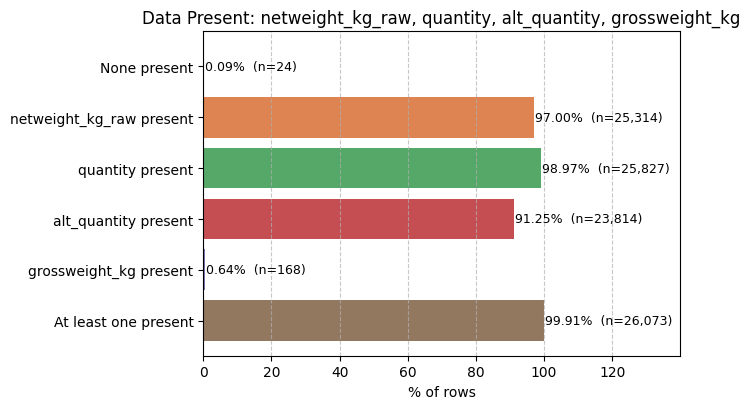

In [73]:
import importlib
import vacoda.visualization.distributions
importlib.reload(vacoda.visualization.distributions)
from vacoda.visualization.distributions import plot_data_coverage_bar
weight_cols = ['netweight_kg_raw', 'quantity', 'alt_quantity', 'grossweight_kg']

plot_data_coverage_bar(df, cols=weight_cols, criteria="presence")

In [76]:
mask = (
    (df['netweight_kg_raw'] > 0) &
    (df['quantity'].notna()) &
    (df['quantity'] > 0) &
    (df['quantity_unit_code'] == 8) &
    (
        abs(df['netweight_kg_raw'] - df['quantity']) /
        df['netweight_kg_raw']
        > 0.01   # 1% difference threshold
    )
)

df[mask][['netweight_kg_raw', 'quantity', 'quantity_unit_code']]

,netweight_kg_raw,quantity,quantity_unit_code
18,3.500,28.000,8
19,79740.906,18830.906,8
20,3.500,28.000,8
36,3.500,28.000,8
37,79740.906,18830.906,8
...,...,...,...
19305,898126.000,30379.250,8
19316,898126.000,30379.250,8
19317,898126.000,30379.250,8
19320,898126.000,30379.250,8


In [90]:
df['flow_desc'].value_counts()

flow_desc
Import                                      15101
Export                                       5913
Foreign Import                               2667
Domestic Export                              1865
Re-import                                     404
Re-export                                     103
Import of goods for inward processing          22
Import of goods after outward processing       12
Export of goods for outward processing          8
Export of goods after inward processing         2
Name: count, dtype: int64

In [92]:
print(2+8+12+22+103+404)
print(26097-25589)

551
508


In [ ]:
def calculate_matching_percentage(
    df,
    weight_col="netweight_kg_raw",
    compare_col="alt_quantity",
    unit_col=None,
    unit_value=None,
    rel_tol=0.01,
):
    """
    Compare two weight-like fields and compute match/mismatch rates.

    Supports both:
    - quantity + unit column
    - direct weight columns (no unit)

    Parameters
    ----------
    df : pd.DataFrame
    weight_col : str
    compare_col : str
    unit_col : str or None
    unit_value : int or None
    rel_tol : float

    Returns
    -------
    dict
    """

    # Base validity
    valid_mask = (
        (df[weight_col] > 0) &
        (df[compare_col].notna()) &
        (df[compare_col] > 0)
    )

    # Optional unit filter
    if unit_col is not None and unit_value is not None:
        print(f"Applying unit filter: {unit_col} == {unit_value}")
        valid_mask &= (df[unit_col] == unit_value)

    valid_df = df[valid_mask]

    if len(valid_df) == 0:
        return {
            "n_valid": 0,
            "match_%": None,
            "mismatch_%": None,
        }

    # Relative difference
    rel_diff = (
        (valid_df[weight_col] - valid_df[compare_col]).abs()
        / valid_df[weight_col]
    )

    mismatch_mask = rel_diff > rel_tol
    match_mask = ~mismatch_mask

    return {
        "n_valid": len(valid_df),
        "match_%": match_mask.mean() * 100,
        "mismatch_%": mismatch_mask.mean() * 100,
    }

In [86]:
calculate_matching_percentage(
    df,
    weight_col="netweight_kg_raw",
    compare_col="grossweight_kg",
    unit_col=None,
    unit_value=None,
    rel_tol=0.01,
)

{'n_valid': 156,
 'match_%': np.float64(41.66666666666667),
 'mismatch_%': np.float64(58.333333333333336)}

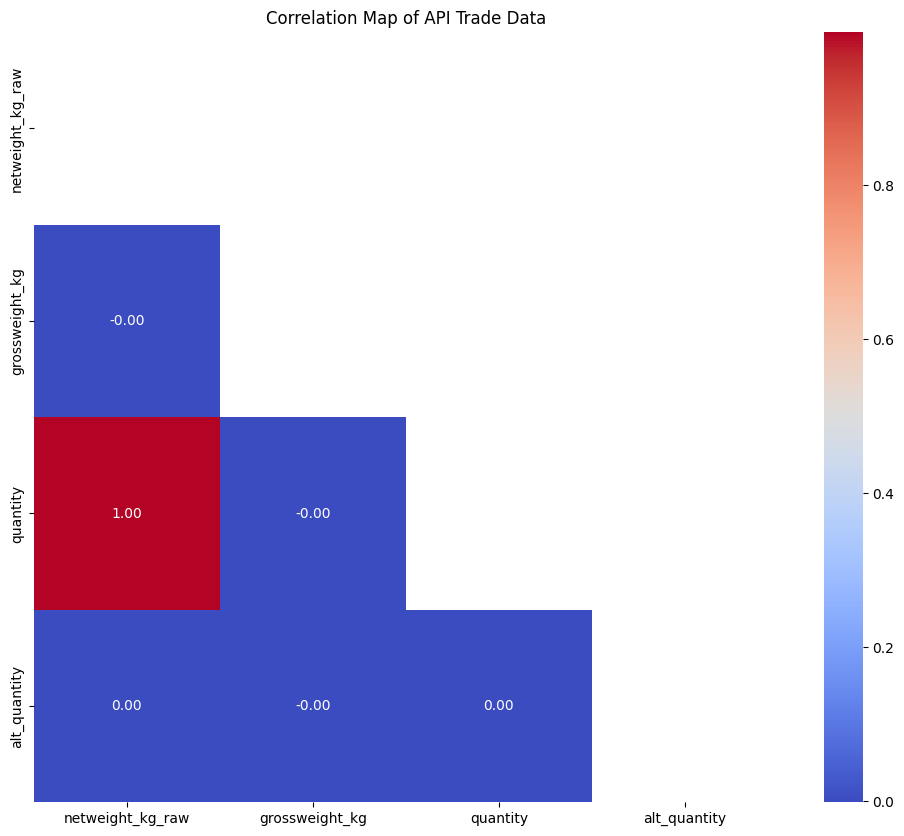

In [95]:

from vacoda.visualization.relationships import plot_correlation_map
Weight_columns = ['netweight_kg_raw', 'grossweight_kg', 'quantity', 'alt_quantity']
mask = (df['quantity_unit_code'] == 8) | (df['alt_quantity_unit_code'] == 8) | (df['grossweight_kg'] > 0)

plot_correlation_map(df[mask][Weight_columns], title='Correlation Map of API Trade Data')

In [49]:
df[(df['netweight_kg_raw']>0) & (df['quantity_unit_abbr'] != "kg") & (df['grossweight_kg']>0)][['quantity', 'netweight_kg_raw','grossweight_kg', 'quantity_unit_abbr']].head(20)

,quantity,netweight_kg_raw,grossweight_kg,quantity_unit_abbr
6854,0.0,990543.557,987220.86,NaN
6855,0.0,68740.330,65512.47,NaN


In [69]:
## lets make this a function to check the percentage 

def check_weight_quantity_match(df, feature_names=['netweight_kg_raw', 'quantity'], unit_feature= 'quantity_unit_abbr', unit='kg'):
     matching_rows = df[(df[feature_names[0]] > 0) & 
                        (df[unit_feature] == unit) & 
                        (df[feature_names[0]] == df[feature_names[1]])]
     mismatching_rows = df[(df[feature_names[0]] > 0) & 
                           (df[unit_feature] == unit) & (df[feature_names[0]] != df[feature_names[1]])]
     total_rows = len(matching_rows) + len(mismatching_rows)
     print(f"Matching rows for {feature_names[0]} and {feature_names[1]}: {len(matching_rows)} ({len(matching_rows)/total_rows*100:.2f}%)")
     print(f"Mismatching rows for {feature_names[0]} and {feature_names[1]}: {len(mismatching_rows)} ({len(mismatching_rows)/total_rows*100:.2f}%)")
     

## lets check the percentage when both netweight_kg_raw & quantity exist with the condition that quantity_unit_abbr is kg, how often they match and how often mistmatch
check_weight_quantity_match(df, feature_names=['netweight_kg_raw', 'alt_quantity'], unit_feature='alt_quantity_unit_abbr', unit='kg')

Matching rows for netweight_kg_raw and alt_quantity: 4377 (94.78%)
Mismatching rows for netweight_kg_raw and alt_quantity: 241 (5.22%)


In [63]:
df[(df['netweight_kg_raw'] > 0) & 
                        (df['quantity_unit_abbr'] == 'kg') & 
                        (df['netweight_kg_raw'] != df['quantity'])][['quantity', 'netweight_kg_raw','grossweight_kg', 'quantity_unit_abbr', 'alt_quantity', 'alt_quantity_unit_abbr']].head(10)

,quantity,netweight_kg_raw,grossweight_kg,quantity_unit_abbr,alt_quantity,alt_quantity_unit_abbr
18,28.000,3.500,0.0,kg,28.0,kg
19,18830.906,79740.906,0.0,kg,17917.0,kg
20,28.000,3.500,0.0,kg,28.0,kg
36,28.000,3.500,0.0,kg,28.0,kg
37,18830.906,79740.906,0.0,kg,17917.0,kg
38,28.000,3.500,0.0,kg,28.0,kg
1176,22073.723,45621.723,0.0,kg,5019.0,kg
1194,22073.723,45621.723,0.0,kg,5019.0,kg
2533,39662.000,37451.000,NaN,kg,39662.0,kg
2566,1.000,3.000,NaN,kg,1.0,kg


In [55]:
check_weight_quantity_match(df, feature_names=['netweight_kg_raw', 'alt_quantity'], 
                            unit_feature='quantity_unit_abbr', unit='kg')

Matching rows for netweight_kg_raw and alt_quantity: 4439 (17.55%)
Mismatching rows for netweight_kg_raw and alt_quantity: 20857 (82.45%)


### Evaluated Diagnostics


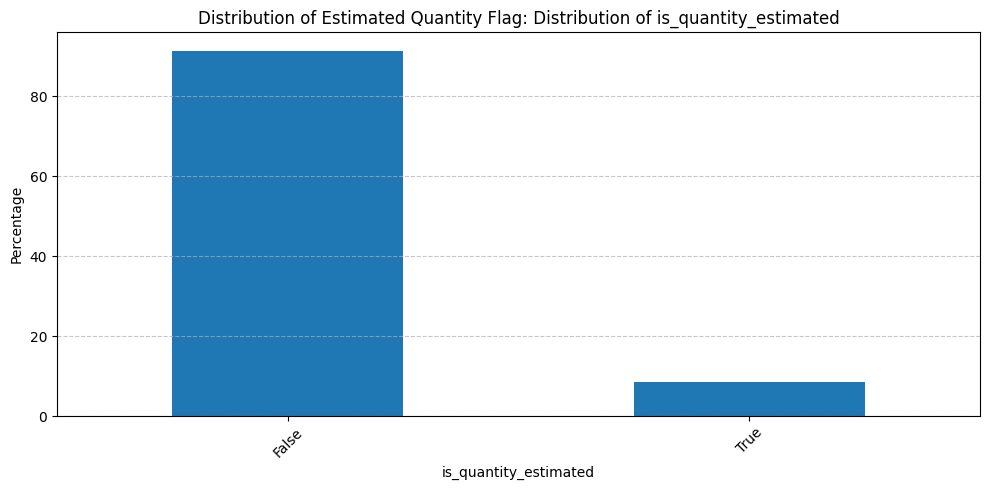

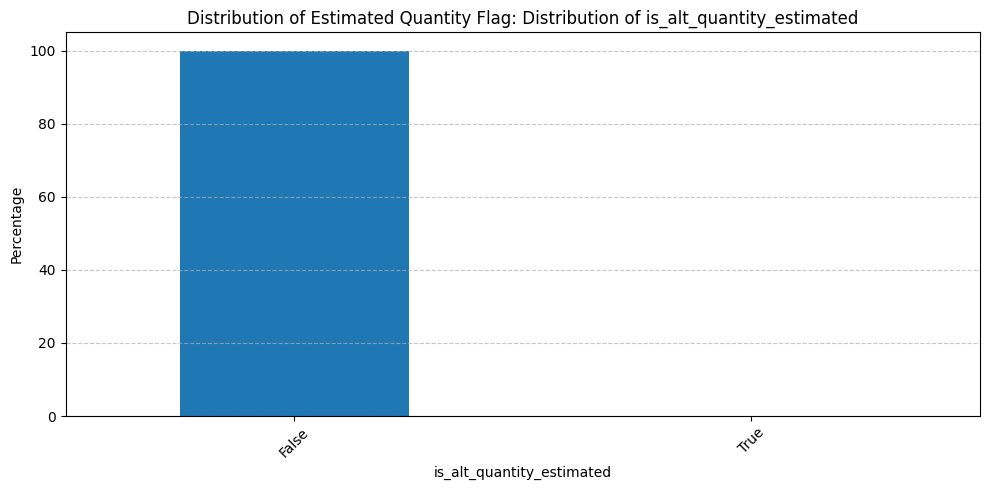

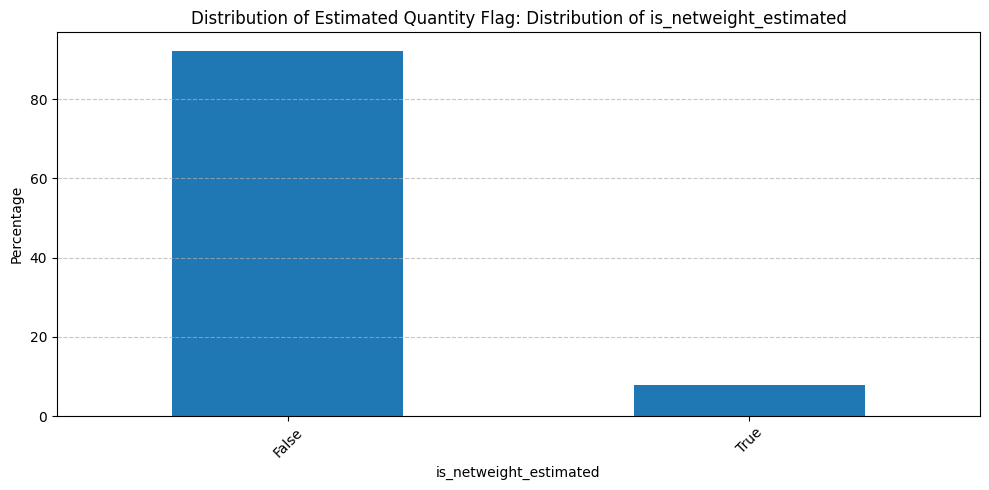

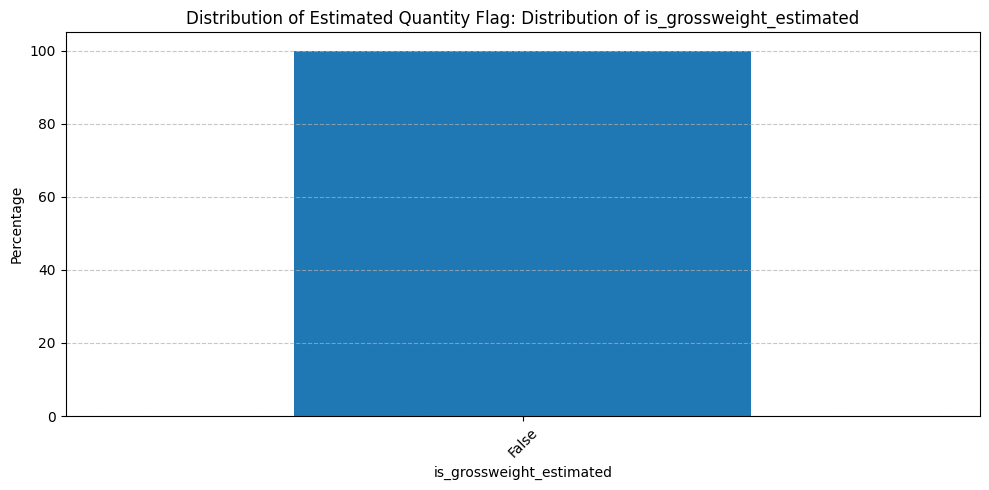

In [2]:
from vacoda.visualization.distributions import plot_bar_distributions
Wright_flag_columns = ['is_quantity_estimated', 'is_alt_quantity_estimated', 'is_netweight_estimated', 'is_grossweight_estimated']
plot_bar_distributions(df, features_list=Wright_flag_columns, show_percent=True,  title='Distribution of Estimated Quantity Flag') 

### Netweight Candidate Selection

In [6]:
import numpy as np
import pandas as pd

def build_evaluation_base(
    df,
    target_col="netweight_kg_raw",
):
    return df.loc[
        df[target_col].notna()
        & (df[target_col] > 0)
    ].copy()


base = build_evaluation_base(df)

KG_CODE = 8

def _evaluate_one_candidate(
    df,
    candidate_col,
    unit_col=None,
    target_col="netweight_kg_raw",
    value_col="value_usd_raw",
    kg_code=KG_CODE,
):
    mask = (
        df[target_col].notna()
        & (df[target_col] > 0)
        & df[candidate_col].notna()
        & (df[candidate_col] > 0)
    )
    if unit_col is not None:
        mask &= df[unit_col].eq(kg_code)

    if mask.sum() == 0:
        return pd.Series({
            "coverage_pct": 0.0,
            "value_usd_pct": 0.0,
            "exact_match_pct": np.nan,
            "median_ape": np.nan,
            "p90_ape": np.nan,
            "match_1pct": np.nan,
            "match_5pct": np.nan,
            "match_10pct": np.nan,
            "median_log_price_gap": np.nan,
        })

    eligible = df.loc[mask].copy()
    cand = eligible[candidate_col].astype(float)
    true = eligible[target_col].astype(float)

    exact_match = cand.eq(true)
    ape = (cand - true).abs() / true

    price_mask = eligible[value_col].notna() & (eligible[value_col] > 0)
    if price_mask.any():
        implied_price = eligible.loc[price_mask, value_col].astype(float) / cand.loc[price_mask]
        true_price = eligible.loc[price_mask, value_col].astype(float) / true.loc[price_mask]
        log_price_gap = (np.log(implied_price) - np.log(true_price)).abs()
        median_log_price_gap = log_price_gap.median()
    else:
        median_log_price_gap = np.nan

    return pd.Series({
        "coverage_pct": mask.mean() * 100,
        "value_usd_pct": price_mask.mean() * 100,
        "exact_match_pct": exact_match.mean() * 100,
        "median_ape": ape.median() * 100,
        "p90_ape": ape.quantile(0.90) * 100,
        "match_1pct": (ape <= 0.01).mean() * 100,
        "match_5pct": (ape <= 0.05).mean() * 100,
        "match_10pct": (ape <= 0.10).mean() * 100,
        "median_log_price_gap": median_log_price_gap,
    })

def evaluate_candidate(
    df,
    candidate_cols=None,
    unit_cols=None,
    target_col="netweight_kg_raw",
    value_col="value_usd_raw",
    kg_code=KG_CODE,
):
    """
    Evaluate multiple candidate columns and return one diagnostics table.

    This keeps the notebook call-site compact while preserving a small
    per-candidate helper for the actual metric computation.
    """
    if candidate_cols is None:
        candidate_cols = ["quantity", "alt_quantity", "grossweight_kg"]
    if unit_cols is None:
        unit_cols = ["quantity_unit_code", "alt_quantity_unit_code", None]
    if len(candidate_cols) != len(unit_cols):
        raise ValueError("candidate_cols and unit_cols must have the same length")

    diagnostics = pd.DataFrame({
        candidate_col: _evaluate_one_candidate(
            df,
            candidate_col=candidate_col,
            unit_col=unit_col,
            target_col=target_col,
            value_col=value_col,
            kg_code=kg_code,
        )
        for candidate_col, unit_col in zip(candidate_cols, unit_cols)
    }).T

    return diagnostics.sort_values(
        by=["exact_match_pct", "match_5pct", "coverage_pct", "median_log_price_gap"],
        ascending=[False, False, False, True],
    )

diagnostics = evaluate_candidate(
    base,
    candidate_cols=["quantity", "alt_quantity", "grossweight_kg"],
    unit_cols=["quantity_unit_code", "alt_quantity_unit_code", None],
)

diagnostics

,coverage_pct,value_usd_pct,exact_match_pct,median_ape,p90_ape,match_1pct,match_5pct,match_10pct,median_log_price_gap
quantity,99.928893,100.0,99.683744,0.000000,0.00000,99.715370,99.754902,99.762808,0.000000
alt_quantity,17.986095,100.0,96.134417,0.000000,0.00000,97.364375,98.089172,98.286844,0.000000
grossweight_kg,0.616260,100.0,40.384615,3.448276,87.11595,41.666667,59.615385,62.820513,0.033902


In [7]:
def rank_netweight_candidates(diagnostics_df, return_all_metrics=True):
    """
    Rank candidates for sequential recovery using a compact decision subset.

    The input diagnostics table may contain richer metrics for analysis;
    only a few are used here for the actual ordering.
    """
    ranked = diagnostics_df.copy()
    ranked["exact_match_pct"] = ranked["exact_match_pct"].fillna(-1.0)
    ranked["match_5pct"] = ranked["match_5pct"].fillna(-1.0)
    ranked["coverage_pct"] = ranked["coverage_pct"].fillna(0.0)
    ranked["value_usd_pct"] = ranked["value_usd_pct"].fillna(0.0)
    ranked["median_log_price_gap"] = ranked["median_log_price_gap"].fillna(np.inf)

    ranked = ranked.sort_values(
        by=["exact_match_pct", "match_5pct", "coverage_pct", "value_usd_pct", "median_log_price_gap"],
        ascending=[False, False, False, False, True],
    )

    ranked["selection_rank"] = range(1, len(ranked) + 1)
    preferred_order = ranked.index.tolist()
    print("Recommended candidate order:", preferred_order)

    ranking_view_cols = [
        "selection_rank",
        "coverage_pct",
        "value_usd_pct",
        "exact_match_pct",
        "match_5pct",
        "median_log_price_gap",
    ]

    if return_all_metrics:
        return ranked

    return ranked[ranking_view_cols]


candidate_ranking = rank_netweight_candidates(diagnostics)
candidate_ranking[[
    "selection_rank",
    "coverage_pct",
    "value_usd_pct",
    "exact_match_pct",
    "match_5pct",
    "median_log_price_gap",
]]

Recommended candidate order: ['quantity', 'alt_quantity', 'grossweight_kg']


,selection_rank,coverage_pct,value_usd_pct,exact_match_pct,match_5pct,median_log_price_gap
quantity,1,99.928893,100.0,99.683744,99.754902,0.000000
alt_quantity,2,17.986095,100.0,96.134417,98.089172,0.000000
grossweight_kg,3,0.616260,100.0,40.384615,59.615385,0.033902


In [8]:
import pandas as pd

def build_evaluation_base(
    df,
    target_col="netweight_kg_raw",
):
    return df.loc[
        df[target_col].notna()
        & (df[target_col] > 0)
    ].copy()


base = build_evaluation_base(df)
KG_CODE = 8
def evaluate_candidate_with_estimation_penalty(
    df,
    candidate_cols=None,
    unit_cols=None,
    estimation_flag_cols=None,
    target_col="netweight_kg_raw",
    value_col="value_usd_raw",
    kg_code=KG_CODE,
):
    """
    Extends evaluate_candidate to include estimation contamination metrics.
    Shows what % of matched rows have estimated values, degrading trust score.
    """
    if candidate_cols is None:
        candidate_cols = ["quantity", "alt_quantity", "grossweight_kg"]
    if unit_cols is None:
        unit_cols = ["quantity_unit_code", "alt_quantity_unit_code", None]
    if estimation_flag_cols is None:
        # Map each candidate to its estimation flag
        estimation_flag_cols = [
            "is_quantity_estimated",
            "is_alt_quantity_estimated",
            "is_grossweight_estimated",
        ]

    base_diagnostics = evaluate_candidate(
        df, candidate_cols, unit_cols, target_col, value_col, kg_code
    )

    # Add estimation contamination rate per candidate
    for cand_col, flag_col in zip(candidate_cols, estimation_flag_cols):
        if flag_col in df.columns:
            mask = df[cand_col].notna() & (df[cand_col] > 0)
            estimated_pct = df.loc[mask, flag_col].mean() * 100
            base_diagnostics.loc[cand_col, "estimated_pct"] = estimated_pct
        else:
            base_diagnostics.loc[cand_col, "estimated_pct"] = np.nan

    # Reliability score: penalize exact_match_pct by estimation contamination
    base_diagnostics["reliability_score"] = (
        base_diagnostics["exact_match_pct"] 
        * (1 - base_diagnostics["estimated_pct"].fillna(0) / 100)
    )

    return base_diagnostics.sort_values("reliability_score", ascending=False)


diagnostics_with_penalty = evaluate_candidate_with_estimation_penalty(
    base,
    candidate_cols=["quantity", "alt_quantity", "grossweight_kg"],
    unit_cols=["quantity_unit_code", "alt_quantity_unit_code", None],
)

diagnostics_with_penalty[[
    "coverage_pct", "exact_match_pct", "match_5pct",
    "estimated_pct", "reliability_score", "median_log_price_gap"
]]

,coverage_pct,exact_match_pct,match_5pct,estimated_pct,reliability_score,median_log_price_gap
alt_quantity,17.986095,96.134417,98.089172,0.00000,96.134417,0.000000
quantity,99.928893,99.683744,99.754902,6.73229,92.972746,0.000000
grossweight_kg,0.616260,40.384615,59.615385,0.00000,40.384615,0.033902


In [9]:
# Compare accuracy on estimated vs non-estimated subsets
target_col = "netweight_kg_raw"
for flag_col, cand_col in zip(Wright_flag_columns[:3], ["quantity", "alt_quantity", "grossweight_kg"]):
    if flag_col in df.columns:
        for is_est, label in [(False, "Non-estimated"), (True, "Estimated")]:
            subset = base[base[flag_col] == is_est]
            if len(subset) > 0:
                ape = (subset[cand_col] - subset[target_col]).abs() / subset[target_col]
                print(f"{cand_col} | {label}: n={len(subset)}, median_APE={ape.median()*100:.2f}%")

quantity | Non-estimated: n=23595, median_APE=0.00%
quantity | Estimated: n=1719, median_APE=0.00%
alt_quantity | Non-estimated: n=25312, median_APE=99.83%
alt_quantity | Estimated: n=2, median_APE=nan%
grossweight_kg | Non-estimated: n=23595, median_APE=100.00%
grossweight_kg | Estimated: n=1719, median_APE=100.00%


In [22]:
# Diagnose alt_quantity unit distribution when it diverges from netweight
FEATURE='alt_quantity'
mask = (
    (base[FEATURE] > 0) & 
    (base['netweight_kg_raw'] > 0)
)
ape = (base.loc[mask, FEATURE] - base.loc[mask, 'netweight_kg_raw']).abs() / base.loc[mask, 'netweight_kg_raw']

print(f"{FEATURE} unit distribution where APE > 50%:")
print(base.loc[mask & (ape > 0.5), f'{FEATURE}_unit_abbr'].value_counts())

print(f"\n{FEATURE} unit distribution where APE < 5%:")
print(base.loc[mask & (ape < 0.05), f'{FEATURE}_unit_abbr'].value_counts())

alt_quantity unit distribution where APE > 50%:
alt_quantity_unit_abbr
m?         18290
kg            64
u             30
m             12
l              4
GT             2
1000 KG        2
Name: count, dtype: int64

alt_quantity unit distribution where APE < 5%:
alt_quantity_unit_abbr
kg    4466
m?      73
l        1
Name: count, dtype: int64


In [ ]:
FEATURE_UNIT='quantity_unit_code'
FEATURE_UNIT_ESTIMATED = 'is_quantity_estimated'
mask_cand = base[FEATURE].notna() & (base[FEATURE] > 0)
mask_cmp = mask_cand & base["netweight_kg_raw"].notna() & (base["netweight_kg_raw"] > 0)
mask_kg = mask_cand & base[FEATURE_UNIT].eq(8)

for name, mask in {
    "cand": mask_cand,
    "cmp": mask_cmp,
    "kg": mask_kg,
}.items():
    s = base.loc[mask, FEATURE_UNIT_ESTIMATED]
    print(f"\n{name} rows={mask.sum()}")
    print(s.value_counts(dropna=False))


cand rows=23127
is_quantity_estimated
False    22251
True       876
Name: count, dtype: int64

cmp rows=23127
is_quantity_estimated
False    22251
True       876
Name: count, dtype: int64

kg rows=23125
is_quantity_estimated
False    22249
True       876
Name: count, dtype: int64


In [34]:
df[df["quantity_unit_code"] > 0]["quantity_unit_code"].value_counts()

quantity_unit_code
8     25735
12       96
Name: count, dtype: int64

In [29]:
FEATURE_UNIT = "quantity_unit_code"
FEATURE_UNIT_ESTIMATED = "is_quantity_estimated"

mask_cand = base[FEATURE].notna() & (base[FEATURE] > 0)
mask_kg = mask_cand & base[FEATURE_UNIT].eq(8)

for name, mask in {
    "cand": mask_cand,
    "kg": mask_kg,
}.items():
    s = base.loc[mask, FEATURE_UNIT_ESTIMATED]
    print(f"\n{name} rows={mask.sum()}")
    print(s.value_counts(dropna=False))
    print(f"estimated_pct={s.eq(True).mean() * 100:.2f}%")


cand rows=23127
is_quantity_estimated
False    22251
True       876
Name: count, dtype: int64
estimated_pct=3.79%

kg rows=23125
is_quantity_estimated
False    22249
True       876
Name: count, dtype: int64
estimated_pct=3.79%


### Evaluation vs Units

In [36]:
import pandas as pd

KG_CODE = 8

anchor = df.loc[
    df["netweight_kg_raw"].notna()
    & (df["netweight_kg_raw"] > 0)
    & df["is_netweight_estimated"].eq(False)
].copy()

soft_reference = df.loc[
    df["netweight_kg_raw"].notna()
    & (df["netweight_kg_raw"] > 0)
    & df["is_netweight_estimated"].eq(True)
].copy()

recovery_pool = df.loc[
    df["netweight_kg_raw"].isna()
    | (df["netweight_kg_raw"] <= 0)
].copy()

print("anchor rows:", len(anchor))
print("netweight estimated rows:", len(soft_reference))
print("recovery_pool rows:", len(recovery_pool))


def evaluate_candidate_flag_effect_on_anchor(
    df,
    candidate_col,
    candidate_flag_col,
    unit_col=None,
    kg_code=KG_CODE,
    target_col="netweight_kg_raw",
    value_col="value_usd_raw",
):
    mask = (
        df[target_col].notna()
        & (df[target_col] > 0)
        & df[candidate_col].notna()
        & (df[candidate_col] > 0)
        & df[value_col].notna()
        & (df[value_col] > 0)
    )

    if unit_col is not None:
        mask &= df[unit_col].eq(kg_code)

    work = df.loc[mask, [candidate_col, candidate_flag_col, target_col, value_col]].copy()
    if work.empty:
        return pd.DataFrame()

    work["candidate_price_per_kg"] = work[value_col] / work[candidate_col]
    work["target_price_per_kg"] = work[value_col] / work[target_col]
    work["ape"] = (work[candidate_col] - work[target_col]).abs() / work[target_col]
    work["match_5pct"] = work["ape"].le(0.05)
    work["exact_match"] = work[candidate_col].eq(work[target_col])
    work["log_price_gap"] = (
        np.log(work["candidate_price_per_kg"]) - np.log(work["target_price_per_kg"])
    ).abs()

    return (
        work.groupby(candidate_flag_col, dropna=False)
        .agg(
            rows=(candidate_col, "size"),
            median_candidate_price_per_kg=("candidate_price_per_kg", "median"),
            median_target_price_per_kg=("target_price_per_kg", "median"),
            median_log_price_gap=("log_price_gap", "median"),
            median_ape_pct=("ape", lambda s: s.median() * 100),
            match_5pct=("match_5pct", lambda s: s.mean() * 100),
            exact_match_pct=("exact_match", lambda s: s.mean() * 100),
        )
        .reset_index()
    )

anchor rows: 23595
netweight estimated rows: 1719
recovery_pool rows: 783


In [37]:
qty_anchor_check = evaluate_candidate_flag_effect_on_anchor(
    anchor,
    candidate_col="quantity",
    candidate_flag_col="is_quantity_estimated",
    unit_col="quantity_unit_code",
)

alt_anchor_check = evaluate_candidate_flag_effect_on_anchor(
    anchor,
    candidate_col="alt_quantity",
    candidate_flag_col="is_alt_quantity_estimated",
    unit_col="alt_quantity_unit_code",
)

gross_anchor_check = evaluate_candidate_flag_effect_on_anchor(
    anchor,
    candidate_col="grossweight_kg",
    candidate_flag_col="is_grossweight_estimated",
    unit_col=None,
)

display(qty_anchor_check)
display(alt_anchor_check)
display(gross_anchor_check)

,is_quantity_estimated,rows,median_candidate_price_per_kg,median_target_price_per_kg,median_log_price_gap,median_ape_pct,match_5pct,exact_match_pct
0,False,23593,0.550374,0.549333,0.0,0.0,99.762641,99.686348


,is_alt_quantity_estimated,rows,median_candidate_price_per_kg,median_target_price_per_kg,median_log_price_gap,median_ape_pct,match_5pct,exact_match_pct
0,False,4451,0.586271,0.581818,0.0,0.0,98.741856,98.337452


,is_grossweight_estimated,rows,median_candidate_price_per_kg,median_target_price_per_kg,median_log_price_gap,median_ape_pct,match_5pct,exact_match_pct
0,False,92,0.6071,0.908827,0.0,0.0,84.782609,68.478261


In [39]:
def debug_candidate_flag_filters(
    df,
    candidate_col,
    candidate_flag_col,
    unit_col=None,
    kg_code=8,
    target_col="netweight_kg_raw",
    value_col="value_usd_raw",
):
    checks = {
        "anchor_target_ok": df[target_col].notna() & (df[target_col] > 0),
        "candidate_ok": df[candidate_col].notna() & (df[candidate_col] > 0),
        "value_ok": df[value_col].notna() & (df[value_col] > 0),
    }

    if unit_col is not None:
        checks["unit_is_kg"] = df[unit_col].eq(kg_code)

    out = []
    for flag_value in sorted(df[candidate_flag_col].dropna().unique().tolist()):
        flag_mask = df[candidate_flag_col].eq(flag_value)
        row = {
            candidate_flag_col: flag_value,
            "all_rows": int(flag_mask.sum()),
        }
        running = flag_mask.copy()
        for name, check_mask in checks.items():
            running &= check_mask
            row[f"after_{name}"] = int(running.sum())
        out.append(row)

    display(pd.DataFrame(out))

    print(f"\nRaw flag distribution for {candidate_flag_col}:")
    print(df[candidate_flag_col].value_counts(dropna=False))

In [40]:
debug_candidate_flag_filters(
    anchor,
    candidate_col="quantity",
    candidate_flag_col="is_quantity_estimated",
    unit_col="quantity_unit_code",
)

debug_candidate_flag_filters(
    anchor,
    candidate_col="alt_quantity",
    candidate_flag_col="is_alt_quantity_estimated",
    unit_col="alt_quantity_unit_code",
)

debug_candidate_flag_filters(
    anchor,
    candidate_col="grossweight_kg",
    candidate_flag_col="is_grossweight_estimated",
    unit_col=None,
)

,is_quantity_estimated,all_rows,after_anchor_target_ok,after_candidate_ok,after_value_ok,after_unit_is_kg
0,False,23595,23595,23593,23593,23593



Raw flag distribution for is_quantity_estimated:
is_quantity_estimated
False    23595
Name: count, dtype: int64


,is_alt_quantity_estimated,all_rows,after_anchor_target_ok,after_candidate_ok,after_value_ok,after_unit_is_kg
0,False,23593,23593,22251,22251,4451
1,True,2,2,0,0,0



Raw flag distribution for is_alt_quantity_estimated:
is_alt_quantity_estimated
False    23593
True         2
Name: count, dtype: int64


,is_grossweight_estimated,all_rows,after_anchor_target_ok,after_candidate_ok,after_value_ok
0,False,23595,23595,92,92



Raw flag distribution for is_grossweight_estimated:
is_grossweight_estimated
False    23595
Name: count, dtype: int64


In [11]:
def diagnose_candidate_unit_alignment(
    df,
    candidate_col,
    target_col="netweight_kg_raw",
    unit_col=None,
    high_ape_threshold=0.50,
    low_ape_threshold=0.05,
    min_positive=True,
    normalize=False,
    top_n=None,
    verbose=True,
):
    """
    Diagnose how a weight candidate behaves against a target, split by APE bands.

    Returns a dictionary with:
    - summary: one-row DataFrame of aggregate counts/shares
    - high_ape_unit_counts: unit distribution where APE > high_ape_threshold
    - low_ape_unit_counts: unit distribution where APE < low_ape_threshold
    - ape_by_unit: per-unit APE summary table
    - eligible_mask: boolean mask for rows used
    - ape: row-level APE Series for eligible rows
    """
    mask = df[target_col].notna() & df[candidate_col].notna()

    if min_positive:
        mask &= (df[target_col] > 0) & (df[candidate_col] > 0)

    eligible = df.loc[mask].copy()

    if eligible.empty:
        empty = pd.Series(dtype="int64")
        return {
            "summary": pd.DataFrame([{
                "candidate_col": candidate_col,
                "target_col": target_col,
                "eligible_rows": 0,
                "high_ape_rows": 0,
                "low_ape_rows": 0,
                "high_ape_pct": np.nan,
                "low_ape_pct": np.nan,
                "median_ape_pct": np.nan,
            }]),
            "high_ape_unit_counts": empty,
            "low_ape_unit_counts": empty,
            "ape_by_unit": pd.DataFrame(),
            "eligible_mask": mask,
            "ape": pd.Series(dtype="float64"),
        }

    ape = (eligible[candidate_col].astype(float) - eligible[target_col].astype(float)).abs() / eligible[target_col].astype(float)

    high_mask = ape > high_ape_threshold
    low_mask = ape < low_ape_threshold

    summary = pd.DataFrame([{
        "candidate_col": candidate_col,
        "target_col": target_col,
        "eligible_rows": int(len(eligible)),
        "high_ape_rows": int(high_mask.sum()),
        "low_ape_rows": int(low_mask.sum()),
        "high_ape_pct": high_mask.mean() * 100,
        "low_ape_pct": low_mask.mean() * 100,
        "median_ape_pct": ape.median() * 100,
    }])

    if unit_col is not None and unit_col in eligible.columns:
        high_ape_unit_counts = eligible.loc[high_mask, unit_col].value_counts(normalize=normalize, dropna=False)
        low_ape_unit_counts = eligible.loc[low_mask, unit_col].value_counts(normalize=normalize, dropna=False)

        ape_by_unit = (
            eligible.assign(_ape=ape)
            .groupby(unit_col, dropna=False)["_ape"]
            .agg(
                n="size",
                median_ape="median",
                p90_ape=lambda s: s.quantile(0.90),
                match_5pct=lambda s: (s < 0.05).mean(),
                high_ape_rate=lambda s: (s > 0.50).mean(),
            )
            .sort_values(["median_ape", "n"], ascending=[True, False])
        )

        ape_by_unit["median_ape"] *= 100
        ape_by_unit["p90_ape"] *= 100
        ape_by_unit["match_5pct"] *= 100
        ape_by_unit["high_ape_rate"] *= 100
    else:
        high_ape_unit_counts = pd.Series(dtype="int64")
        low_ape_unit_counts = pd.Series(dtype="int64")
        ape_by_unit = pd.DataFrame()

    if top_n is not None:
        high_ape_unit_counts = high_ape_unit_counts.head(top_n)
        low_ape_unit_counts = low_ape_unit_counts.head(top_n)

    if verbose:
        print(summary.to_string(index=False))
        if unit_col is not None and unit_col in eligible.columns:
            print(f"\n{candidate_col} | unit distribution where APE > {high_ape_threshold:.0%}:")
            print(high_ape_unit_counts)
            print(f"\n{candidate_col} | unit distribution where APE < {low_ape_threshold:.0%}:")
            print(low_ape_unit_counts)

    return {
        "summary": summary,
        "high_ape_unit_counts": high_ape_unit_counts,
        "low_ape_unit_counts": low_ape_unit_counts,
        "ape_by_unit": ape_by_unit,
        "eligible_mask": mask,
        "ape": ape,
    }

In [19]:
df['quantity_unit_abbr'].value_counts()

quantity_unit_abbr
kg    25735
m?       96
Name: count, dtype: int64

In [18]:
alt_quantity_diag = diagnose_candidate_unit_alignment(
    base,
    candidate_col="quantity",
    target_col="netweight_kg_raw",
    unit_col="quantity_unit_abbr",
    high_ape_threshold=0.50,
    low_ape_threshold=0.05,
    top_n=10,
    verbose=True,
)

alt_quantity_diag["summary"]
alt_quantity_diag["ape_by_unit"].head(10)

candidate_col       target_col  eligible_rows  high_ape_rows  low_ape_rows  high_ape_pct  low_ape_pct  median_ape_pct
     quantity netweight_kg_raw          25296             50         25234       0.19766    99.754902             0.0

quantity | unit distribution where APE > 50%:
quantity_unit_abbr
kg    50
Name: count, dtype: int64

quantity | unit distribution where APE < 5%:
quantity_unit_abbr
kg    25234
Name: count, dtype: int64


,n,median_ape,p90_ape,match_5pct,high_ape_rate
quantity_unit_abbr,,,,,
kg,25296,0.0,0.0,99.754902,0.19766


In [13]:
def run_candidate_unit_diagnostics(
    df,
    candidates,
    target_col="netweight_kg_raw",
    unit_cols=None,
    high_ape_threshold=0.50,
    low_ape_threshold=0.05,
    verbose=False,
):
    if unit_cols is None:
        unit_cols = [None] * len(candidates)

    results = {}
    summaries = []

    for candidate_col, unit_col in zip(candidates, unit_cols):
        diag = diagnose_candidate_unit_alignment(
            df,
            candidate_col=candidate_col,
            target_col=target_col,
            unit_col=unit_col,
            high_ape_threshold=high_ape_threshold,
            low_ape_threshold=low_ape_threshold,
            verbose=verbose,
        )
        results[candidate_col] = diag
        summaries.append(diag["summary"])

    summary_df = pd.concat(summaries, ignore_index=True)
    return results, summary_df.sort_values(
        ["low_ape_pct", "median_ape_pct"],
        ascending=[False, True],
    )

In [15]:
candidate_unit_results, candidate_unit_summary = run_candidate_unit_diagnostics(
    base,
    candidates=["quantity", "alt_quantity", "grossweight_kg"],
    unit_cols=["quantity_unit_abbr", "alt_quantity_unit_abbr", None],
    target_col="netweight_kg_raw",
    verbose=False,
)

candidate_unit_summary

,candidate_col,target_col,eligible_rows,high_ape_rows,low_ape_rows,high_ape_pct,low_ape_pct,median_ape_pct
0,quantity,netweight_kg_raw,25296,50,25234,0.197660,99.754902,0.000000
2,grossweight_kg,netweight_kg_raw,156,40,93,25.641026,59.615385,3.448276
1,alt_quantity,netweight_kg_raw,23127,18404,4540,79.577982,19.630735,99.824756


In [17]:
print(candidate_unit_results["alt_quantity"]["high_ape_unit_counts"])
print(candidate_unit_results["alt_quantity"]["low_ape_unit_counts"])

alt_quantity_unit_abbr
m?         18290
kg            64
u             30
m             12
l              4
GT             2
1000 KG        2
Name: count, dtype: int64
alt_quantity_unit_abbr
kg    4466
m?      73
l        1
Name: count, dtype: int64


In [47]:
df[df['alt_quantity_unit_abbr']=='1000 KG'][['netweight_kg_raw', 'quantity', 'alt_quantity', 'grossweight_kg']].head(20)

,netweight_kg_raw,quantity,alt_quantity,grossweight_kg
16296,309436.3,309436.3,309.436,0.0
17287,309436.3,309436.3,309.436,0.0


### Multi REcoery Cycle

In [4]:
from vacoda.utils.diagnostics import run_multi_recovery_cycles
# Run multi recovery cycles on the standardized DataFrame
df= run_multi_recovery_cycles(df, 
                                main_feature="netweight_kg_raw",
                                supporting_features=["quantity", "alt_quantity", "grossweight_kg"],
                                unit_features=["quantity_unit_code", "alt_quantity_unit_code", None],
                                recovery_col_prefix="netweight_kg",
                                recovery_flag_prefix="netweight_kg_recovery_flag",
                                kg_unit_code=8,
                                logger=None
                                )

In [5]:
df.shape

(26097, 49)

In [6]:
df.head(4)

,type_code,freq_code,ref_period_id,year,month,period,reporter_code,reporter_iso,reporter_desc,flow_code,...,grossweight_kg,is_grossweight_estimated,cif_value_usd,fob_value_usd,value_usd_raw,legacy_estimation_flag,is_reported,is_aggregate,netweight_kg,netweight_kg_recovery_flag
0,C,A,20140101,2014,52,2014,8,ALB,Albania,M,...,NaN,False,73102.0,NaN,73102.0,0,True,False,151953.0,False
1,C,A,20140101,2014,52,2014,12,DZA,Algeria,M,...,NaN,False,397168.0,NaN,397168.0,0,True,False,735109.0,False
2,C,A,20140101,2014,52,2014,24,AGO,Angola,M,...,NaN,False,351573.0,NaN,351573.0,0,True,False,291819.0,False
3,C,A,20140101,2014,52,2014,31,AZE,Azerbaijan,M,...,NaN,False,130391.0,NaN,130391.0,0,True,False,196191.0,False


In [40]:
df[df['netweight_kg_recovery_flag']==True][['quantity', 'netweight_kg_raw','grossweight_kg','netweight_kg', 'quantity_unit_abbr']].head(20)

,quantity,netweight_kg_raw,grossweight_kg,netweight_kg,quantity_unit_abbr
201,1.240000e+02,NaN,78068.0,7.806800e+04,m?
202,0.000000e+00,NaN,6424508.0,6.424508e+06,NaN
228,1.240000e+02,NaN,78068.0,7.806800e+04,m?
229,0.000000e+00,NaN,6424508.0,6.424508e+06,NaN
336,0.000000e+00,NaN,0.0,1.000000e+00,NaN
363,0.000000e+00,NaN,0.0,1.000000e+00,NaN
1206,0.000000e+00,NaN,0.0,3.957888e+07,NaN
1260,5.220633e+04,NaN,NaN,5.220633e+04,kg
1337,0.000000e+00,NaN,1.0,1.000000e+00,NaN
1355,0.000000e+00,NaN,1.0,1.000000e+00,NaN


### Preprocessing

In [10]:
## lets remove all constant columns
constant_cols = [col for col in df.columns if df[col].nunique() == 1]
print(f"Constant columns to drop: {constant_cols}")

## Lets make Global variable for the constant columns
COMMODITY_CODE = df['commodity_code'].iloc[0] if 'commodity_code' in df.columns else None
COMMODITY_DESC = df['commodity_desc'].iloc[0] if 'commodity_desc' in df.columns else None


Constant columns to drop: ['type_code', 'freq_code', 'month', 'partner_code', 'partner_iso', 'partner_desc', 'hs_code_search', 'is_original_classification', 'commodity_code', 'commodity_desc', 'aggregation_level', 'is_leaf', 'MosCode', 'is_grossweight_estimated']


In [48]:
df[constant_cols].head(1)

,type_code,freq_code,month,partner_code,partner_iso,partner_desc,hs_code_search,is_original_classification,commodity_code,commodity_desc,aggregation_level,is_leaf,MosCode,is_grossweight_estimated
0,C,A,52,0,W00,World,HS,True,441012,"Oriented strand board (OSB) of wood, whether o...",6,True,0,False


In [11]:
## lets delete constant columns from the dataframe
df.drop(columns=constant_cols, inplace=True)
df.shape


(26097, 35)

In [102]:
df.head(2)

,ref_period_id,year,period,reporter_code,reporter_iso,reporter_desc,flow_code,flow_desc,partner2_code,partner2_iso,...,is_netweight_estimated,grossweight_kg,cif_value_usd,fob_value_usd,value_usd_raw,legacy_estimation_flag,is_reported,is_aggregate,netweight_kg_raw_recovery_flag_grossweight_kg,netweight_kg_raw_recovered_from_grossweight_kg
0,20140101,2014,2014,8,ALB,Albania,M,Import,0,W00,...,False,NaN,73102.0,NaN,73102.0,0,True,False,False,151953.0
1,20140101,2014,2014,12,DZA,Algeria,M,Import,0,W00,...,False,NaN,397168.0,NaN,397168.0,0,True,False,False,735109.0


In [19]:
## Some Wish columsn to drop
TO_SEPERATE = ["reporter_iso", 'reporter_desc', 'partner2_iso', 'partner2_desc', 'flow_desc','ref_period_id', 'period', 'custom_desc', 'MotDesc', 'quantity_unit_abbr','alt_quantity_unit_abbr', 'netweight_kg_raw']

In [20]:
df[TO_SEPERATE].head(2)

,reporter_iso,reporter_desc,partner2_iso,partner2_desc,flow_desc,ref_period_id,period,custom_desc,MotDesc,quantity_unit_abbr,alt_quantity_unit_abbr,netweight_kg_raw
0,ALB,Albania,W00,World,Import,20140101,2014,TOTAL CPC,TOTAL MOT,kg,NaN,151953.0
1,DZA,Algeria,W00,World,Import,20140101,2014,TOTAL CPC,TOTAL MOT,kg,NaN,735109.0


In [21]:
all_cols = df.columns.tolist()
df_seperate = df[TO_SEPERATE]
print(df_seperate.shape)
## Lets make fresh dataframe without these columns
used_cols = [c for c in all_cols if c not in TO_SEPERATE]
df_new = df[used_cols]

print(df_new.shape)

(26097, 12)
(26097, 23)


In [16]:
df_new.iloc[:, 10:22].head(4)

,alt_quantity_unit_code,alt_quantity,is_alt_quantity_estimated,netweight_kg_raw,is_netweight_estimated,grossweight_kg,cif_value_usd,fob_value_usd,value_usd_raw,legacy_estimation_flag,is_reported,is_aggregate
0,-1,NaN,False,151953.0,False,NaN,73102.0,NaN,73102.0,0,True,False
1,-1,NaN,False,735109.0,False,NaN,397168.0,NaN,397168.0,0,True,False
2,-1,NaN,False,291819.0,False,NaN,351573.0,NaN,351573.0,0,True,False
3,-1,NaN,False,196191.0,False,NaN,130391.0,NaN,130391.0,0,True,False


In [17]:
## lets find whoch columsn have only nan values
nan_cols = [col for col in df_new.columns if df_new[col].isna().all()]
print(f"Columns with all NaN values: {nan_cols}")

Columns with all NaN values: []


In [22]:
## LEts check which two columns are highly correletad to each other?
## how to check if any two given columns have same values in whole dataframe
[(col1, col2) 
 for col1 in df_new.columns if df_new[col1].dtype in ['int64', 'float64']
 for col2 in df_new.columns if df_new[col2].dtype in ['int64', 'float64']
 if col1 != col2 and df_new[col1].corr(df_new[col2]) > 0.9]


[('quantity', 'value_usd_raw'),
 ('quantity', 'netweight_kg'),
 ('fob_value_usd', 'value_usd_raw'),
 ('value_usd_raw', 'quantity'),
 ('value_usd_raw', 'fob_value_usd'),
 ('value_usd_raw', 'netweight_kg'),
 ('netweight_kg', 'quantity'),
 ('netweight_kg', 'value_usd_raw')]

In [92]:
df_new[['netweight_kg_raw', 'quantity']].corr()

,netweight_kg_raw,quantity
netweight_kg_raw,1.000000,0.998312
quantity,0.998312,1.000000


### Lets redefine flow_code value map


In [27]:
flow_codes = df_new['flow_code'].unique().tolist()
flow_codes

['M', 'X', 'DX', 'RM', 'RX', 'FM', 'MIP', 'XOP', 'MOP', 'XIP']

In [28]:
## lets make flow_map so we could change flow_code to integer
flow_map = {code: idx for idx, code in enumerate(flow_codes)}

## lets apply flow map to flow_code column
df_new['flow_code'] = df_new['flow_code'].map(flow_map)
df_new['flow_code'].unique()

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

### Lets make correlation map

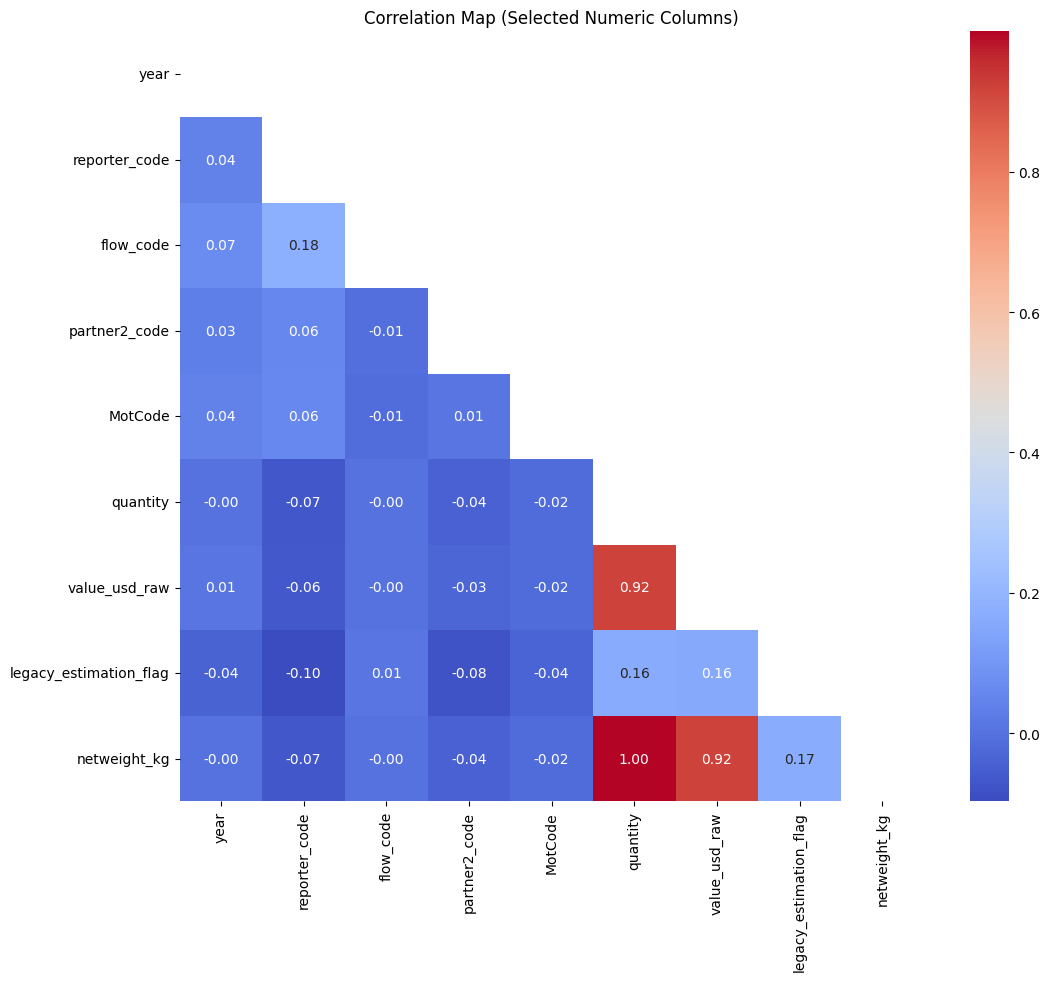

In [41]:
## Plot Correlation map for all numeric columns & show only the bottom right triangle of the correlation matrix
## lets make this a function so we could reuse it later
def plot_correlation_map(df, title='Correlation Map'):
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
    plt.figure(figsize=(12, 10))
    corr_matrix = df[numeric_cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', mask=mask)
    plt.title(title)
    plt.show()

numeric_cols = df_new.select_dtypes(include=['int64', 'float64']).columns
Elimination_List = ['quantity_unit_code', 'alt_quantity','alt_quantity_unit_code', 'grossweight_kg', 'cif_value_usd', 'fob_value_usd']
numeric_cols = [col for col in numeric_cols if col not in Elimination_List]
plot_correlation_map(df_new[numeric_cols], title='Correlation Map (Selected Numeric Columns)')

In [96]:
## lets check the cases where the netweight and quantity differs
df_new[df_new['netweight_kg_raw'] != df_new['quantity']][['netweight_kg_raw', 'quantity']]

,netweight_kg_raw,quantity
18,3.500,28.000
19,79740.906,18830.906
20,3.500,28.000
36,3.500,28.000
37,79740.906,18830.906
...,...,...
24871,NaN,0.000
24878,NaN,0.000
24879,NaN,0.000
24880,NaN,0.000


In [22]:
## how to check if any two given columns have same values in whole dataframe
[(col1, col2) 
 for col1 in df.columns 
 for col2 in df.columns 
 if col1 != col2 and df[col1].equals(df[col2])]

[('year', 'period'), ('period', 'year')]

In [15]:
df['flow_code'].value_counts()

flow_code
M      15101
X       5913
FM      2667
DX      1865
RM       404
RX       103
MIP       22
MOP       12
XOP        8
XIP        2
Name: count, dtype: int64

In [16]:
df['flow_desc'].value_counts()

flow_desc
Import                                      15101
Export                                       5913
Foreign Import                               2667
Domestic Export                              1865
Re-import                                     404
Re-export                                     103
Import of goods for inward processing          22
Import of goods after outward processing       12
Export of goods for outward processing          8
Export of goods after inward processing         2
Name: count, dtype: int64

In [14]:
df.columns.to_list()

['ref_period_id',
 'year',
 'period',
 'reporter_code',
 'reporter_iso',
 'reporter_desc',
 'flow_code',
 'flow_desc',
 'partner2_code',
 'partner2_iso',
 'partner2_desc',
 'hs_code_short',
 'custom_code',
 'custom_desc',
 'MotCode',
 'MotDesc',
 'quantity_unit_code',
 'quantity_unit_abbr',
 'quantity',
 'estimation_code',
 'alt_quantity_unit_code',
 'alt_quantity_unit_abbr',
 'alt_quantity',
 'is_alt_quantity_estimated',
 'netweight_kg_raw',
 'is_netweight_estimated',
 'grossweight_kg',
 'cif_value_usd',
 'fob_value_usd',
 'value_usd_raw',
 'legacy_estimation_flag',
 'is_reported',
 'is_aggregate']

In [4]:
## Check if any rows have missing values in key columns
df.isnull().sum()[['reporter_desc', 'partner_desc', 'trade_flow', 'trade_value_usd']]

KeyError: "None of [Index(['reporter', 'partner', 'trade_flow', 'trade_value_usd'], dtype='str')] are in the [index]"

In [3]:
# EDA: Overview
print(df.info())
display(df.describe(include='all', datetime_is_numeric=True))
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nUnique values per column:")
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 26097 entries, 0 to 26096
Data columns (total 47 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   type_code                   26097 non-null  str    
 1   freq_code                   26097 non-null  str    
 2   ref_period_id               26097 non-null  int64  
 3   year                        26097 non-null  int64  
 4   month                       26097 non-null  int64  
 5   period                      26097 non-null  int64  
 6   reporter_code               26097 non-null  int64  
 7   reporter_iso                26097 non-null  str    
 8   reporter_desc               26097 non-null  str    
 9   flow_code                   26097 non-null  str    
 10  flow_desc                   26097 non-null  str    
 11  partner_code                26097 non-null  int64  
 12  partner_iso                 26097 non-null  str    
 13  partner_desc                26097 non-null

TypeError: NDFrame.describe() got an unexpected keyword argument 'datetime_is_numeric'

In [ ]:
# EDA: Visualizations

# Example: Distribution of trade values
if 'value_usd' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.histplot(df['value_usd'].dropna(), bins=50, kde=True)
    plt.title('Distribution of Trade Value (USD)')
    plt.xlabel('Trade Value (USD)')
    plt.ylabel('Frequency')
    plt.show()

# Example: Top 10 trading partners (if partner_code or partner_desc exists)
partner_col = 'partner_code' if 'partner_code' in df.columns else ('partner_desc' if 'partner_desc' in df.columns else None)
if partner_col:
    top_partners = df[partner_col].value_counts().head(10)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_partners.values, y=top_partners.index)
    plt.title('Top 10 Trading Partners')
    plt.xlabel('Number of Records')
    plt.ylabel('Partner')
    plt.show()

## Define and Use Global Constants for EDA

Store important or constant values as global variables for clarity and reuse in your analysis.

In [12]:
# Define global variables/constants for EDA
REQUIRED_COLUMNS = ['CmdCode', 'CmdDesc']
COMMODITY_CODE = df_api['CmdCode'].unique()
COMMODITY_DESC = df_api['CmdDesc'].unique()

print(f"Unique commodity codes: {COMMODITY_CODE}")
print(f"Unique commodity descriptions: {COMMODITY_DESC}")

Unique commodity codes: [441012]
Unique commodity descriptions: <ArrowStringArray>
['Oriented strand board (OSB) of wood, whether or not agglomerated with resins or other organic binding substances']
Length: 1, dtype: str


## Delete Constant columns

In [11]:
## Lets find the constant columns in the API data
constant_columns = [col for col in df_api.columns if df_api[col].nunique() == 1]
print(f"Constant columns in API data: {constant_columns}")

Constant columns in API data: ['TypeCode', 'FreqCode', 'RefMonth', 'PartnerCode', 'PartnerISO', 'PartnerDesc', 'ClassificationSearchCode', 'IsOriginalClassification', 'CmdCode', 'CmdDesc', 'aggrLevel', 'IsLeaf', 'MosCode', 'IsGrossWgtEstimated']


In [14]:
## Lets define a dataframe without constant columns
df = df_api.drop(columns=constant_columns)
print(f"Shape of dataframe without constant columns: {df.shape}")

Shape of dataframe without constant columns: (26097, 33)


## Further EDA: Commodity Analysis and Data Quality Checks

Explore the distribution, missingness, and relationships of key commodity fields in your API data.

In [ ]:
# 1. Check for missing values in key columns
for col in REQUIRED_COLUMNS:
    missing = df[col].isnull().sum()
    print(f"Missing values in {col}: {missing}")

Missing values in CmdCode: 0
Missing values in CmdDesc: 0


In [ ]:
# 2. Frequency of each commodity code
top_commodities = df_api['CmdCode'].value_counts().head(10)
print("Top 10 commodity codes:")
print(top_commodities)

In [16]:
# 3. Distribution of trade value by commodity (if Value or value_usd exists)
value_col = 'Value' if 'Value' in df_api.columns else ('value_usd' if 'value_usd' in df_api.columns else None)
if value_col:
    import matplotlib.pyplot as plt
    import seaborn as sns
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='CmdCode', y=value_col, data=df_api[df_api['CmdCode'].isin(top_commodities.index)])
    plt.title('Trade Value Distribution for Top 10 Commodities')
    plt.xlabel('Commodity Code')
    plt.ylabel('Trade Value')
    plt.xticks(rotation=45)
    plt.show()
else:
    print('No trade value column found for distribution plot.')

No trade value column found for distribution plot.


In [ ]:
# 4. Cross-tabulation: Commodity vs. Partner (if partner column exists)
partner_col = 'PartnerCode' if 'PartnerCode' in df_api.columns else ('partner_code' if 'partner_code' in df_api.columns else None)
if partner_col:
    crosstab = pd.crosstab(df_api['CmdCode'], df_api[partner_col])
    print('Commodity vs. Partner cross-tabulation (top 5 rows):')
    display(crosstab.head())
else:
    print('No partner column found for cross-tabulation.')

## Focused EDA: NetWeight and Related Features

Analyze the distribution, missingness, and relationships of netweight and related columns in your API data.

In [19]:
df.columns.to_list()

['RefPeriodId',
 'RefYear',
 'Period',
 'ReporterCode',
 'ReporterISO',
 'ReporterDesc',
 'FlowCode',
 'FlowDesc',
 'Partner2Code',
 'Partner2ISO',
 'Partner2Desc',
 'ClassificationCode',
 'CustomsCode',
 'CustomsDesc',
 'MotCode',
 'MotDesc',
 'QtyUnitCode',
 'QtyUnitAbbr',
 'Qty',
 'IsQtyEstimated',
 'AltQtyUnitCode',
 'AltQtyUnitAbbr',
 'AltQty',
 'IsAltQtyEstimated',
 'NetWgt',
 'IsNetWgtEstimated',
 'GrossWgt',
 'Cifvalue',
 'Fobvalue',
 'PrimaryValue',
 'LegacyEstimationFlag',
 'IsReported',
 'IsAggregate']

In [20]:
# 1. Check for netweight-related columns
netweight_cols = [col for col in df.columns if 'netwgt' in col.lower() or 'qty' in col.lower()]
print(f"Netweight-related columns: {netweight_cols}")

Netweight-related columns: ['QtyUnitCode', 'QtyUnitAbbr', 'Qty', 'IsQtyEstimated', 'AltQtyUnitCode', 'AltQtyUnitAbbr', 'AltQty', 'IsAltQtyEstimated', 'NetWgt', 'IsNetWgtEstimated']


In [21]:
df[netweight_cols].head()

,QtyUnitCode,QtyUnitAbbr,Qty,IsQtyEstimated,AltQtyUnitCode,AltQtyUnitAbbr,AltQty,IsAltQtyEstimated,NetWgt,IsNetWgtEstimated
0,8,kg,151953.0,False,-1,NaN,NaN,False,151953.0,False
1,8,kg,735109.0,False,-1,NaN,NaN,False,735109.0,False
2,8,kg,291819.0,False,-1,NaN,NaN,False,291819.0,False
3,8,kg,196191.0,False,-1,NaN,NaN,False,196191.0,False
4,8,kg,13909211.7,False,8,kg,13909211.7,False,13909211.7,False


In [26]:
netweight_float_cols = [col for col in netweight_cols if df[col].dtype in ['float64', 'int64']]
print(f"Netweight-related columns with numeric types: {netweight_float_cols}")

Netweight-related columns with numeric types: ['QtyUnitCode', 'Qty', 'AltQtyUnitCode', 'AltQty', 'NetWgt']


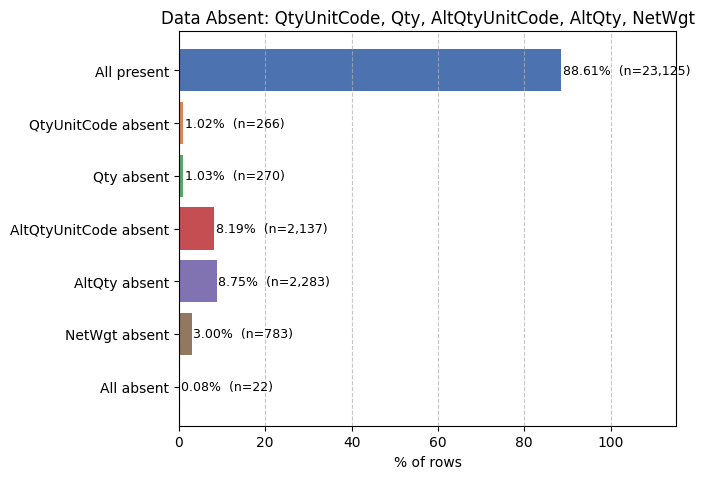

In [27]:
from vacoda.visualization.distributions import plot_data_coverage_bar
plot_data_coverage_bar(df, cols=netweight_float_cols)

In [ ]:
## Lets try to gain netweight from quantity and unit if netweight is missing

In [ ]:


# 2. Missing values and basic stats for netweight columns
for col in netweight_cols:
    print(f"\nColumn: {col}")
    print(f"  Missing: {df_api[col].isnull().sum()} / {len(df_api)}")
    print(f"  Min: {df_api[col].min()}  Max: {df_api[col].max()}  Mean: {df_api[col].mean()}  Median: {df_api[col].median()}")
    print(f"  Unique: {df_api[col].nunique()}")

# 3. Distribution plot for netweight (if present)
main_weight_col = netweight_cols[0] if netweight_cols else None
if main_weight_col:
    import matplotlib.pyplot as plt
    import seaborn as sns
    plt.figure(figsize=(10, 5))
    sns.histplot(df_api[main_weight_col].dropna(), bins=50, kde=True)
    plt.title(f'Distribution of {main_weight_col}')
    plt.xlabel(main_weight_col)
    plt.ylabel('Frequency')
    plt.show()
else:
    print('No netweight column found for distribution plot.')

# 4. Relationship between netweight and value (if both exist)
value_col = 'Value' if 'Value' in df_api.columns else ('value_usd' if 'value_usd' in df_api.columns else None)
if main_weight_col and value_col:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x=df_api[main_weight_col], y=df_api[value_col], alpha=0.3)
    plt.title(f'{main_weight_col} vs. {value_col}')
    plt.xlabel(main_weight_col)
    plt.ylabel(value_col)
    plt.show()
else:
    print('No value column found for netweight-value scatter plot.')